# Reproduce the paper: radar water levels for rating transfer, model diagnosis and forecast updating on the Semliki River

**Kakooza, C. and Nafula, M. (2026).** *Radar water-level observations for rating transfer, model diagnosis and forecast error correction in an operational flood forecasting system: the Semliki River, Uganda.* Zenodo. https://doi.org/10.5281/zenodo.24487523

Run it top to bottom (*Run all*); it needs `numpy`, `pandas` and `matplotlib` and takes a few seconds, locally or in Google Colab.

| Step | Reproduces |
|---|---|
| 1 | the routed rating R2026-11 at the radar against R2026-10 at Bweramule (Table 1, Fig. 2) |
| 2 | the size of the unsteady-flow loop at the radar (Jones formula) |
| 3 | the model structure above the radar and the components of the flow (Section 2) |
| 4 | the event analysis of the radar record: rise, quickflow, runoff coefficient, Clark R from the recession (Table 2) |
| 5 | the structure tests on the radar and the Bweramule scores (Table 3, Fig. 3) |
| 6 | the rain conditioning, present and candidate structure (Table 4) |
| 7 | the correction laws and the memory of the residuals (Table 5) |
| 8 | the 27-forecast test and its skill scores (Table 6, Fig. 4) |
| 9 | the two-part correction on the issue of 20 November 2026 |

The HEC-HMS runs are not repeated here (they need the model): the files in `data/` are their outputs (hourly flow at the radar junction), the published
ratings, the routed steady profiles and the radar record. The HEC-HMS and HEC-RAS models and the Bweramule gaugings are not distributed here;
requests may be addressed to the corresponding author.

## 0. Set-up

In [1]:
import os, sys, json, zipfile, urllib.request
RAW = "https://raw.githubusercontent.com/Kaitale/semliki-sem9.13-radar-rating-assimilation/main/"
if not os.path.isdir("data"):
    if not os.path.exists("data_radar.zip"):
        print("downloading data_radar.zip"); urllib.request.urlretrieve(RAW + "data_radar.zip", "data_radar.zip")
    zipfile.ZipFile("data_radar.zip").extractall(".")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
OUT = os.path.abspath("outputs"); os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#E6EBEF"})
rd = lambda f, **k: pd.read_csv(os.path.join("data", f), **k)

## 1. The rating at the radar (Table 1, Fig. 2)

R2026-11 is the steady water-surface table of the lower-Semliki HEC-RAS model (roughness calibrated to the Bweramule ADCP
gaugings) read at RS 102530, 8.6 km above the gauge; the radar zero is fitted (618.440 m on the model datum, sd 0.085 m).

In [2]:
R11 = rd("rating_R2026-11_radar.csv"); R10 = rd("rating_R2026-10_bweramule.csv"); P = rd("routed_steady_profiles_RS102530_RS93956.csv")
H = rd("rewc01_radar_hourly.csv", index_col=0, parse_dates=True)
def dqdh(h, q, lo, hi):
    s = np.gradient(q, h); m = (q >= lo) & (q <= hi); return s[m].min(), s[m].max()
lo, hi = H.radar_flow_m3s.min(), H.radar_flow_m3s.max()
r_rad = dqdh(R11.radar_reading_m.values, R11.Q_m3s.values, lo - 15, hi + 15)
r_gau = dqdh(R10.gauge_m.values, R10.Q_m3s.values, lo - 15, hi + 15)
print("record: %.1f-%.1f m3/s, mean %.1f, %d hours" % (lo, hi, H.radar_flow_m3s.mean(), len(H)))
print("conveyance per metre over the record range: radar %.0f-%.0f, Bweramule (R2026-10) %.0f-%.0f m3/s per m" % (*r_rad, *r_gau))
pk = H.radar_flow_m3s.idxmax(); w = H[pk - pd.Timedelta(days=4):pk]; tr = w.radar_flow_m3s.idxmin()
dh = H.at[pk, "radar_reading_m"] - H.at[tr, "radar_reading_m"]; dq = H.at[pk, "radar_flow_m3s"] - H.at[tr, "radar_flow_m3s"]
qg = np.interp(np.interp(H.at[tr, "radar_flow_m3s"], R10.Q_m3s, R10.gauge_m) + dh, R10.gauge_m, R10.Q_m3s) - H.at[tr, "radar_flow_m3s"]
print("largest rise %s -> %s: %.2f m on the radar = %.1f m3/s on R2026-11; %.1f m3/s if read on the gauge rating" % (tr, pk, dh, dq, qg))
T2 = pd.DataFrame({"radar reading (m)": np.interp([100, 140, 180, 240, 320, 400], R11.Q_m3s, R11.radar_reading_m).round(2), "flow (m3/s)": [100, 140, 180, 240, 320, 400]}).T
T1 = T2; T1.to_csv(os.path.join(OUT, "table1_rating_points.csv")); T1

record: 131.6-189.5 m3/s, mean 147.8, 1028 hours
conveyance per metre over the record range: radar 107-129, Bweramule (R2026-10) 76-105 m3/s per m
largest rise 2026-11-06 23:00:00 -> 2026-11-09 09:00:00: 0.50 m on the radar = 57.9 m3/s on R2026-11; 44.0 m3/s if read on the gauge rating


,0,1,2,3,4,5
radar reading (m),16.18,16.56,16.9,17.36,17.94,18.45
flow (m3/s),100.00,140.00,180.0,240.00,320.00,400.00


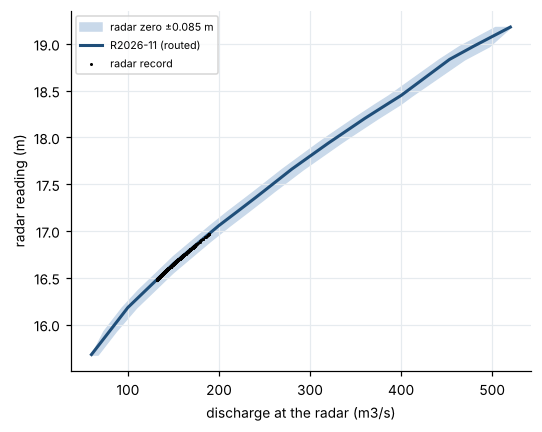

In [3]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.fill_betweenx(R11.radar_reading_m, np.interp(R11.radar_reading_m - 0.085, R11.radar_reading_m, R11.Q_m3s), np.interp(R11.radar_reading_m + 0.085, R11.radar_reading_m, R11.Q_m3s), color="#C9D9EA", label="radar zero ±0.085 m")
ax.plot(R11.Q_m3s, R11.radar_reading_m, color="#1F4E79", lw=2, label="R2026-11 (routed)")
ax.plot(H.radar_flow_m3s, H.radar_reading_m, ".", ms=2, color="k", label="radar record")
ax.set_xlabel("discharge at the radar (m3/s)"); ax.set_ylabel("radar reading (m)"); ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig2_rating.png"), dpi=200)

## 2. The loop at the radar

Jones (1916): *Q*/*Q*_s = [1 + (d*h*/d*t*)/(*S*_0 *c*)]^½ with the slope between radar and gauge and a kinematic celerity.

In [4]:
S0 = float((P.fall_radar_to_gauge_m / 8600).median()); c = 1.8
rate = H.radar_reading_m.rolling(3, center=True).mean().diff().max()          # m per hour, 3-h smoothed
jones = np.sqrt(1 + (rate / 3600) / (S0 * c)) - 1
print("S0 = %.1e; fastest rise %.1f cm/h; Jones term %.1f %% (%.1f m3/s at the peak)" % (S0, 100 * rate, 100 * jones, jones * H.radar_flow_m3s.max()))

S0 = 3.3e-04; fastest rise 3.0 cm/h; Jones term 0.7 % (1.3 m3/s at the peak)


## 3. The model above the radar and the components of its flow

In [5]:
P = rd("hechms_parameters_above_radar.csv")
print("subbasins: %d, %.0f km2" % (len(P), P.area_km2.sum()))
print("constant loss rate: %.1f-%.1f mm/h (%d at 20 mm/h); impervious %s %%" % (P.constant_rate_mm_h.min(), P.constant_rate_mm_h.max(), (P.constant_rate_mm_h >= 19.99).sum(), sorted(P.impervious_pct.unique())))
print("R/(Tc+R): %.3f-%.3f; area-mean R %.0f h, Tc %.0f h; R range %.1f-%.1f h" % ((P.clark_r_h / (P.clark_r_h + P.clark_tc_h)).min(), (P.clark_r_h / (P.clark_r_h + P.clark_tc_h)).max(),
      (P.clark_r_h * P.area_km2).sum() / P.area_km2.sum(), (P.clark_tc_h * P.area_km2).sum() / P.area_km2.sum(), P.clark_r_h[P.area_km2 > 1].min(), P.clark_r_h.max()))
K = rd("model_components_radar_hourly.csv", index_col=0, parse_dates=True)["2026-10-10":]
K.agg(["mean", "min", "max"]).round(1)

subbasins: 40, 5602 km2
constant loss rate: 6.0-20.0 mm/h (4 at 20 mm/h); impervious [np.float64(5.0)] %
R/(Tc+R): 0.750-0.750; area-mean R 62 h, Tc 21 h; R range 11.5-86.5 h


,model_at_radar,lake_edward,direct_runoff,quick_groundwater,slow_groundwater
mean,149.0,47.5,10.2,21.5,56.5
min,136.1,46.0,2.3,16.1,55.6
max,163.1,51.6,20.6,29.7,58.0


## 4. Event analysis of the radar record (Table 2)

Base: the lowest flow of the 12 h before the rise. Quickflow: volume above the base over the area above the radar (6,298 km²).
Clark (1945): R = flow / rate of fall at the inflection point of the falling limb (quickflow, 5-h running mean).

In [6]:
Q = H.radar_flow_m3s.asfreq("h").interpolate(limit=6); Pd = rd("rain_above_radar_daily.csv", index_col=0, parse_dates=True).rain_mm
EV = [("13 Oct", "2026-10-13 11:00", "2026-10-10", "2026-10-17", "2026-10-09", "2026-10-12"), ("9 Nov", "2026-11-09 09:00", "2026-11-06", "2026-11-11", "2026-11-06", "2026-11-08"),
      ("14 Nov", "2026-11-14 01:00", "2026-11-12", "2026-11-17", "2026-11-12", "2026-11-13")]
rows = []
for n, pk, t0, t1, r0, r1 in EV:
    x = Q[t0:t1]; base = x.iloc[:12].min(); vol = (x - base).clip(lower=0).sum() * 3600 / 6298e3
    sm = Q[pk:t1].rolling(5, center=True).mean().dropna() - base; d = sm.diff(); i = d.idxmin()
    rows.append(dict(peak=n, peak_m3s=round(x.max(), 1), base=round(base, 1), rise=round(x.max() - base, 1), quickflow_mm=round(vol, 2), rain_mm=round(Pd[r0:r1].sum(), 1),
                     runoff_coeff=round(vol / Pd[r0:r1].sum(), 3), clark_R_h=round(sm[i] / -d[i], 1)))
T2e = pd.DataFrame(rows).set_index("peak"); T2e.to_csv(os.path.join(OUT, "table2_events.csv")); T2e

,peak_m3s,base,rise,quickflow_mm,rain_mm,runoff_coeff,clark_R_h
peak,,,,,,,
13 Oct,160.9,139.4,21.5,0.72,17.4,0.041,14.8
9 Nov,189.5,133.7,55.8,1.60,25.0,0.064,24.5
14 Nov,174.3,144.3,30.0,0.97,28.1,0.034,24.6


## 5. Structure tests (Table 3, Fig. 3)

In [7]:
ST = rd("structure_tests_hourly.csv", index_col=0, parse_dates=True); B = json.load(open("data/structure_tests_bweramule_scores.json"))
def ev(s):
    out = {}
    for n, pk, t0, t1, *_ in EV:
        o = Q[t0:t1]; m = s[t0:t1]; out[n] = round(m.max(), 0); out["lag " + n + " (h)"] = (m.idxmax() - o.idxmax()).total_seconds() / 3600
    return out
T3 = pd.DataFrame({k: ev(ST[k]) for k in ST.columns}).T[["13 Oct", "9 Nov", "14 Nov", "lag 9 Nov (h)"]]
for k, b in (("present", "present"), ("candidate_imperv8", "H8"), ("imperv10", "G")):
    for m in ("kge", "r", "rmse", "rmse_top10", "bias"): T3.loc[k, "Bweramule " + m] = round(B["bweramule_daily_2023_2025"][b][m], 2)
T3.to_csv(os.path.join(OUT, "table3_structure.csv")); T3

,13 Oct,9 Nov,14 Nov,lag 9 Nov (h),Bweramule kge,Bweramule r,Bweramule rmse,Bweramule rmse_top10,Bweramule bias
present,142.0,150.0,186.0,62.0,0.29,0.30,52.13,82.54,-18.23
R0.11_Tc0.57,141.0,151.0,170.0,0.0,NaN,NaN,NaN,NaN,NaN
R0.11_Tc0.57_fc0.3,141.0,151.0,170.0,0.0,NaN,NaN,NaN,NaN,NaN
candidate_imperv8,155.0,168.0,190.0,-1.0,0.24,0.25,47.36,77.22,-9.37
imperv10,163.0,179.0,203.0,-1.0,0.24,0.24,49.10,76.76,-7.27
imperv15,185.0,205.0,233.0,-1.0,NaN,NaN,NaN,NaN,NaN


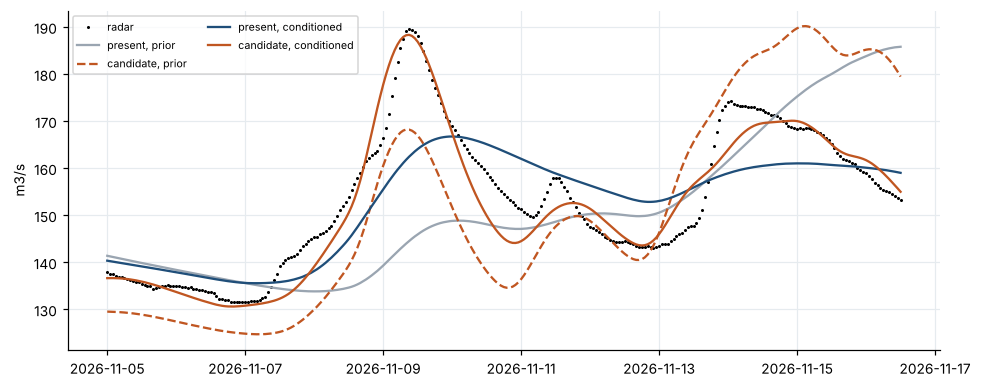

In [8]:
C = rd("conditioning_hourly.csv", index_col=0, parse_dates=True); w0, w1 = "2026-11-05", "2026-11-16 12:00"
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(Q[w0:w1], ".", ms=2, color="k", label="radar")
for k, cl, ls in (("present_prior", "#9aa5b1", "-"), ("candidate_prior", "#C05621", "--"), ("present_conditioned", "#1F4E79", "-"), ("candidate_conditioned", "#C05621", "-")):
    ax.plot(C[k][w0:w1], ls, color=cl, label=k.replace("_", ", "))
ax.set_ylabel("m3/s"); ax.legend(fontsize=7, ncol=2); fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig3_peak.png"), dpi=200)

## 6. Rain conditioning (Table 4)

min Σ (Q_radar − Q_HMS(f))² / (n_c σ_q²) + Σ (f_d − 1)² / σ_f², 0.4 ≤ f_d ≤ 2.5, σ_q = 5 m³/s, n_c = 24, σ_f = 0.5; the last three days held.

In [9]:
def stats(s, o):
    j = pd.concat([s, o], axis=1, keys=["s", "o"], sort=True).dropna()["2026-10-10":"2026-11-20 03:00"]; e = j.s - j.o
    r = np.corrcoef(j.s, j.o)[0, 1]; a = j.s.std() / j.o.std(); b = j.s.mean() / j.o.mean()
    return dict(RMSE=np.sqrt((e ** 2).mean()), r=r, NSE=1 - (e ** 2).sum() / ((j.o - j.o.mean()) ** 2).sum(), KGE=1 - np.sqrt((r - 1) ** 2 + (a - 1) ** 2 + (b - 1) ** 2), alpha=a,
                peak_9Nov=j.s["2026-11-08":"2026-11-10"].max(), peak_14Nov=j.s["2026-11-13":"2026-11-15"].max())
T4 = pd.DataFrame({k: stats(C[k], H.radar_flow_m3s) for k in C.columns}).round(2); T4.to_csv(os.path.join(OUT, "table4_conditioning.csv"))
Fc = rd("rain_factors_conditioned.csv", index_col=0, parse_dates=True)
print("fitted factors (days not held):", {k: (round(v[(v - 1).abs() > 1e-6].min(), 2), round(v[(v - 1).abs() > 1e-6].max(), 2)) for k, v in Fc[:"2026-11-16"].items()})
print("response share at the radar after 1, 2, 3, 5, 10, 20 days:", json.load(open("data/conditioning_settings.json"))["response_share_after_days"]["share"])
T4

fitted factors (days not held): {'present': (np.float64(0.4), np.float64(2.11)), 'candidate': (np.float64(0.4), np.float64(2.32))}
response share at the radar after 1, 2, 3, 5, 10, 20 days: [0.019, 0.096, 0.194, 0.356, 0.58, 0.806]


,present_prior,present_conditioned,candidate_prior,candidate_conditioned
RMSE,16.09,6.41,16.11,5.47
r,0.28,0.76,0.45,0.86
NSE,-1.66,0.58,-1.67,0.69
KGE,0.06,0.66,0.03,0.84
alpha,1.60,0.75,1.80,1.07
peak_9Nov,148.88,166.75,168.23,188.34
peak_14Nov,183.56,161.04,190.20,170.10


## 7. Correction laws and the memory of the residuals (Table 5)

In [10]:
L = json.load(open("data/correction_laws_both_records.json"))
keys = {"ratio, 60 d": "ratio tau60 (now)", "additive, 3 d": "additive tau3", "additive, 20 d": "additive tau20", "two-part: 3-day min, 60 d and 5 d": "two W3 tf5 ts60 min"}
T5 = pd.DataFrame([[k, L[v][2], L[v][3], (L[v][2] + L[v][3]) / 2] for k, v in keys.items()], columns=["law", "radar 2026 hourly", "Bweramule 2023-25 daily", "mean"]).round(2)
T5.to_csv(os.path.join(OUT, "table5_laws.csv"), index=False)
S = rd("hechms_radar_junction_hourly.csv", index_col=0, parse_dates=True)
def acf(s):
    e = (s - H.radar_flow_m3s).dropna()["2026-10-10":].asfreq("h").interpolate(limit=6).dropna().values
    return [round(float(np.mean(e[:-k] * e[k:]) / np.mean(e * e)), 2) for k in (1, 24, 72)]
print("residual correlation after 1 h, 1 d, 3 d: before conditioning", acf(S.prior), "; after (operational)", acf(S.history_matched), "; candidate conditioned", acf(C.candidate_conditioned))
T5

residual correlation after 1 h, 1 d, 3 d: before conditioning [1.0, 0.78, 0.26] ; after (operational) [0.99, 0.13, -0.35] ; candidate conditioned [0.99, 0.03, 0.14]


,law,radar 2026 hourly,Bweramule 2023-25 daily,mean
0,"ratio, 60 d",1.30,1.09,1.19
1,"additive, 3 d",1.08,2.01,1.54
2,"additive, 20 d",1.20,1.08,1.14
3,"two-part: 3-day min, 60 d and 5 d",1.13,1.09,1.11


## 8. Twenty-seven forecasts (Table 6, Fig. 4)

In [11]:
T6 = rd("forecast_test_27_rmse.csv", index_col=0); pers = T6.loc["persistence"]; SS = (1 - (T6 ** 2) / (pers ** 2)).round(2)
ck = [k for k in T6.index if k.startswith("candidate structure, open loop + single term")][0]; pk = [k for k in T6.index if k.startswith("present structure, open loop + single term")][0]
cand, inst = T6.loc[ck], T6.loc["operational from 20 Nov"]
print("candidate vs operational from 20 Nov (% lower RMSE):", (100 * (1 - cand / inst)).round(0).to_dict())
print("MSE skill vs persistence, candidate open loop + single term:", SS.loc[ck].to_dict()); print("present open loop + single term:", SS.loc[pk].to_dict())
print("single-term tau (d):", json.load(open("data/single_term_tau.json"))["tau_days"])
T6.round(1).to_csv(os.path.join(OUT, "table6_rmse.csv")); SS.to_csv(os.path.join(OUT, "table6_skill.csv")); T6.round(1)

candidate vs operational from 20 Nov (% lower RMSE): {'+1 d': -10.0, '+2 d': -1.0, '+3 d': 2.0, '+5 d': 17.0, '+7 d': 30.0}
MSE skill vs persistence, candidate open loop + single term: {'+1 d': 0.02, '+2 d': 0.24, '+3 d': 0.25, '+5 d': 0.02, '+7 d': 0.33}
present open loop + single term: {'+1 d': 0.31, '+2 d': 0.43, '+3 d': 0.37, '+5 d': -0.4, '+7 d': -0.18}
single-term tau (d): {'present': 2.54, 'candidate': 2.33}


,+1 d,+2 d,+3 d,+5 d,+7 d
persistence,10.3,14.8,15.7,12.2,15.4
operational until 20 Nov (ratio 60 d),9.7,14.0,15.9,17.3,23.3
operational from 20 Nov,9.3,12.7,14.0,14.6,18.0
"present structure, model, no update",10.6,10.7,11.9,14.4,16.6
"present structure, model + two-part",9.3,12.9,14.3,16.0,18.7
"present structure, conditioned",12.8,13.3,14.9,18.1,20.1
"present structure, conditioned + two-part",9.1,12.7,14.1,14.8,17.8
"candidate structure, model, no update",12.6,13.2,14.3,12.0,12.5
"candidate structure, model + two-part",11.6,15.6,16.8,20.1,22.2
"candidate structure, conditioned",12.8,14.0,15.8,13.3,14.1


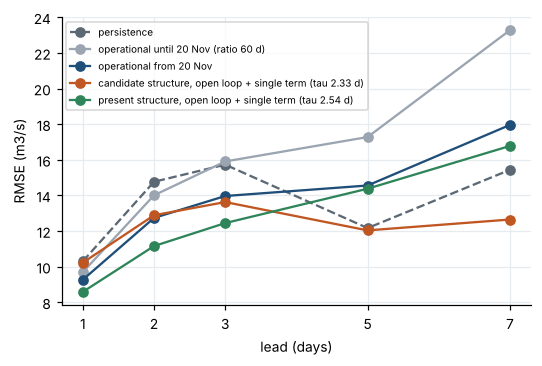

In [12]:
fig, ax = plt.subplots(figsize=(5, 3.4)); L6 = [1, 2, 3, 5, 7]
for k, cl, ls in (("persistence", "#5c6975", "--"), ("operational until 20 Nov (ratio 60 d)", "#9aa5b1", "-"), ("operational from 20 Nov", "#1F4E79", "-"), (ck, "#C05621", "-"), (pk, "#2F855A", "-")):
    ax.plot(L6, T6.loc[k].values, ls, marker="o", color=cl, label=k)
ax.set_xticks(L6); ax.set_xlabel("lead (days)"); ax.set_ylabel("RMSE (m3/s)"); ax.legend(fontsize=6.5); fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig4_skill.png"), dpi=200)

## 9. The two-part correction on the issue of 20 November 2026

*Q*_corr(*t*) = *Q*_HMS(*t*) + *s* e^{−(t−T0)/60 d} + *f* e^{−(t−T0)/5 d}, *s* the smallest misfit of the last three days, *f* the rest.

In [13]:
I = json.load(open("data/issue_20261120.json")); r = I["rerun"]
t = np.arange(0, 7 * 24 + 1); corr = r["slow"] * np.exp(-t / 24 / 60) + r["fast"] * np.exp(-t / 24 / 5)
print("misfit at the issue %.1f m3/s (= radar %.1f - model %.1f); after 1 / 3 / 7 days: %.1f / %.1f / %.1f m3/s" % (corr[0], r["radar"], r["hms_radar"], corr[24], corr[72], corr[-1]))

misfit at the issue -2.9 m3/s (= radar 146.9 - model 149.8); after 1 / 3 / 7 days: -3.3 / -3.9 / -4.4 m3/s


Every output is in `outputs/`.